# Exploration de MovieLens

Les quatre CSV de `ml-latest-small` sont dans `data/raw/`. L'application utilise des favoris et des IDs TMDB. Cette analyse porte sur les notes MovieLens, les genres et la correspondance entre les deux catalogues.

## Données

`movieId` permet de retrouver le même film dans les quatre fichiers. Pour certains films, l'ID TMDB n'est pas renseigné. Les IDs IMDb sont lus comme du texte pour garder les zéros au début. Les dates sont lues en UTC.

In [1]:
from pathlib import Path
import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if
    (p / "data/raw/movies.csv").is_file()
    and (p / "src/data/exploration.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt movies-and-me-recommender.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.exploration import (
    data_quality_report, genre_counts, interaction_tables,
    load_movielens, summarize_dataset,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 12)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")


Python 3.12.7 | pandas 3.0.6 | matplotlib 3.11.2


In [2]:
DATA_DIR = PROJECT_ROOT / "data/raw"
tables = load_movielens(DATA_DIR)
movies, ratings, links, tags = (tables[name] for name in ("movies", "ratings", "links", "tags"))
for name, frame in tables.items():
    display(Markdown(f"### {name}.csv — {len(frame):,} lignes"))
    display(frame.head(3))
display(pd.DataFrame({name: frame.dtypes.astype(str) for name, frame in tables.items()}).fillna("—"))


### movies.csv — 9,742 lignes

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


### ratings.csv — 100,836 lignes

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224


### links.csv — 9,742 lignes

,movieId,imdbId,tmdbId
0,1,0114709,862
1,2,0113497,8844
2,3,0113228,15602


### tags.csv — 3,683 lignes

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992


,movies,ratings,links,tags
genres,string,—,—,—
imdbId,—,—,string,—
movieId,int64,int64,int64,int64
rating,—,float64,—,—
tag,—,—,—,string
timestamp,—,int64,—,int64
title,string,—,—,—
tmdbId,—,—,Int64,—
userId,—,int64,—,int64


## Valeurs manquantes et doublons

Les notes sont vérifiées par couple `(userId, movieId)`. Pour les tags, le texte et la date font aussi partie de la clé : un utilisateur peut ajouter plusieurs tags au même film.

In [3]:
quality = data_quality_report(tables)
display(quality)
missing_by_column = pd.concat(
    [frame.isna().sum().rename(name) for name, frame in tables.items()], axis=1
).T.fillna(0).astype(int)
display(Markdown("Valeurs manquantes par colonne"))
display(missing_by_column)

catalog_ids = set(movies["movieId"])
rating_user_ids = set(ratings["userId"])
reference_checks = pd.Series({
    "ratings : movieId hors catalogue": int((~ratings["movieId"].isin(catalog_ids)).sum()),
    "tags : movieId hors catalogue": int((~tags["movieId"].isin(catalog_ids)).sum()),
    "links : movieId hors catalogue": int((~links["movieId"].isin(catalog_ids)).sum()),
    "films sans ligne links": int((~movies["movieId"].isin(links["movieId"])).sum()),
    "tags : userId absent des ratings": int((~tags["userId"].isin(rating_user_ids)).sum()),
    "notes hors échelle 0.5–5 par pas de 0.5": int((~ratings["rating"].isin([i / 2 for i in range(1, 11)])).sum()),
    "tmdbId renseignés non positifs": int(links["tmdbId"].le(0).sum()),
    "timestamps négatifs (ratings + tags)": int((ratings["timestamp"] < 0).sum() + (tags["timestamp"] < 0).sum()),
}, name="num_anomalies")
display(reference_checks.to_frame())

# Un titre n'est pas un identifiant fiable ; plusieurs films peuvent le partager.
duplicate_titles = movies.loc[movies["title"].duplicated(keep=False)].sort_values("title")
display(Markdown("Titres associés à plusieurs movieId"))
display(duplicate_titles)
print("Titres sans année finale extractible (espaces ignorés) :",
      int(movies["title"].str.strip().str.extract(r"\((\d{4})\)$", expand=False).isna().sum()))


,num_rows,num_columns,missing_cells,duplicate_rows,duplicate_keys
dataset,,,,,
movies,9742,3,0,0,0
ratings,100836,4,0,0,0
links,9742,3,8,0,0
tags,3683,4,0,0,0


Valeurs manquantes par colonne

,movieId,title,genres,userId,rating,timestamp,imdbId,tmdbId,tag
movies,0,0,0,0,0,0,0,0,0
ratings,0,0,0,0,0,0,0,0,0
links,0,0,0,0,0,0,0,8,0
tags,0,0,0,0,0,0,0,0,0


,num_anomalies
ratings : movieId hors catalogue,0
tags : movieId hors catalogue,0
links : movieId hors catalogue,0
films sans ligne links,0
tags : userId absent des ratings,0
notes hors échelle 0.5–5 par pas de 0.5,0
tmdbId renseignés non positifs,0
timestamps négatifs (ratings + tags),0


Titres associés à plusieurs movieId

,movieId,title,genres
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller
650,838,Emma (1996),Comedy|Drama|Romance
5601,26958,Emma (1996),Romance
5854,32600,Eros (2004),Drama
9135,147002,Eros (2004),Drama|Romance
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
6932,64997,War of the Worlds (2005),Action|Sci-Fi


Titres sans année finale extractible (espaces ignorés) : 13


Il manque huit IDs TMDB. Aucun doublon de ligne n'a été trouvé, et toutes les notes, tous les tags et tous les liens correspondent à des films du catalogue.

Certains titres apparaissent avec deux IDs et des genres différents. Pour identifier un film, il vaut donc mieux utiliser `movieId`.

## Notes et activité

Les films sans note restent dans le catalogue et dans le comptage des notes par film. Leur note moyenne n'est pas calculée.

Dans la moyenne générale, les utilisateurs qui ont donné beaucoup de notes comptent davantage. La moyenne des moyennes par utilisateur donne le même poids à chacun.

In [4]:
per_user, per_movie = interaction_tables(movies, ratings)
num_movies, num_users, num_ratings = len(movies), ratings["userId"].nunique(), len(ratings)
no_rating_movies = movies.loc[movies["movieId"].isin(per_movie.index[per_movie["num_ratings"].eq(0)])]
interaction_summary = pd.Series({
    "num_movies": num_movies,
    "num_users_with_ratings": num_users,
    "num_ratings": num_ratings,
    "num_movies_with_ratings": ratings["movieId"].nunique(),
    "num_movies_without_ratings": len(no_rating_movies),
    "global_avg_rating": ratings["rating"].mean(),
    "median_rating": ratings["rating"].median(),
    "avg_ratings_per_user": per_user["num_ratings"].mean(),
    "avg_ratings_per_catalog_movie": per_movie["num_ratings"].mean(),
    "mean_of_user_avg_ratings": per_user["avg_rating"].mean(),
    "mean_of_rated_movie_avg_ratings": per_movie["avg_rating"].mean(),
    "interaction_density": num_ratings / (num_users * num_movies),
    "catalog_fraction_with_at_most_5_ratings": per_movie["num_ratings"].le(5).mean(),
}, name="value")
display(interaction_summary.to_frame())
display(Markdown("Répartition des notes"))
rating_distribution = ratings["rating"].value_counts().sort_index().rename("num_ratings").to_frame()
rating_distribution["fraction"] = rating_distribution["num_ratings"] / num_ratings
display(rating_distribution)


,value
num_movies,9742.000000
num_users_with_ratings,610.000000
num_ratings,100836.000000
num_movies_with_ratings,9724.000000
num_movies_without_ratings,18.000000
global_avg_rating,3.501557
median_rating,3.500000
avg_ratings_per_user,165.304918
avg_ratings_per_catalog_movie,10.350647
mean_of_user_avg_ratings,3.657222


Répartition des notes

,num_ratings,fraction
rating,,
0.5,1370,0.013586
1.0,2811,0.027877
1.5,1791,0.017762
2.0,7551,0.074884
2.5,5550,0.055040
3.0,20047,0.198808
3.5,13136,0.130271
4.0,26818,0.265957
4.5,8551,0.084801


In [5]:
display(Markdown("Par utilisateur"))
display(per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
display(per_user.sort_values("num_ratings", ascending=False).head(10))
display(Markdown("Par film, films non notés inclus"))
display(per_movie.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
display(movies.merge(per_movie, on="movieId", validate="one_to_one")
        .sort_values("num_ratings", ascending=False).head(10))
display(Markdown("Films sans notes"))
display(no_rating_movies)


Par utilisateur

,num_ratings,avg_rating
count,610.000000,610.000000
mean,165.304918,3.657222
std,269.480584,0.480635
min,20.000000,1.275000
25%,35.000000,3.360000
50%,70.500000,3.694385
75%,168.000000,3.997500
90%,400.300000,4.215079
95%,610.750000,4.368132
99%,1256.220000,4.669255


,num_ratings,avg_rating
userId,,
414,2698,3.391957
599,2478,2.642050
474,2108,3.398956
448,1864,2.847371
274,1346,3.235884
610,1302,3.688556
68,1260,3.233730
380,1218,3.673235
606,1115,3.657399


Par film, films non notés inclus

,num_ratings,avg_rating
count,9742.000000,9724.000000
mean,10.350647,3.262448
std,22.384729,0.869874
min,0.000000,0.500000
25%,1.000000,2.800000
50%,3.000000,3.416667
75%,9.000000,3.911765
90%,27.000000,4.192405
95%,47.000000,4.500000
99%,114.180000,5.000000


,movieId,title,genres,num_ratings,avg_rating
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.164134
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.197068
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.161290
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.192446
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.231076
418,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238,3.750000
97,110,Braveheart (1995),Action|Drama|War,237,4.031646
507,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224,3.970982
461,527,Schindler's List (1993),Drama|War,220,4.225000


Films sans notes

,movieId,title,genres
816,1076,"Innocents, The (1961)",Drama|Horror|Thriller
2211,2939,Niagara (1953),Drama|Thriller
2499,3338,For All Mankind (1989),Documentary
2587,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama
3118,4194,I Know Where I'm Going! (1945),Drama|Romance|War
4037,5721,"Chosen, The (1981)",Drama
4506,6668,"Road Home, The (Wo de fu qin mu qin) (1999)",Drama|Romance
4598,6849,Scrooge (1970),Drama|Fantasy|Musical
4704,7020,Proof (1991),Comedy|Drama|Romance
5020,7792,"Parallax View, The (1974)",Thriller


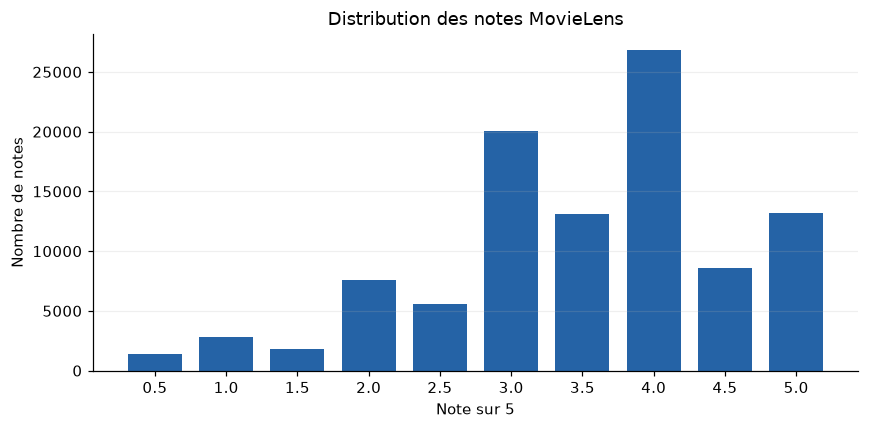

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rating_distribution.index, rating_distribution["num_ratings"], width=0.38, color="#2563a6")
ax.set(title="Distribution des notes MovieLens", xlabel="Note sur 5", ylabel="Nombre de notes")
ax.set_xticks(rating_distribution.index)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


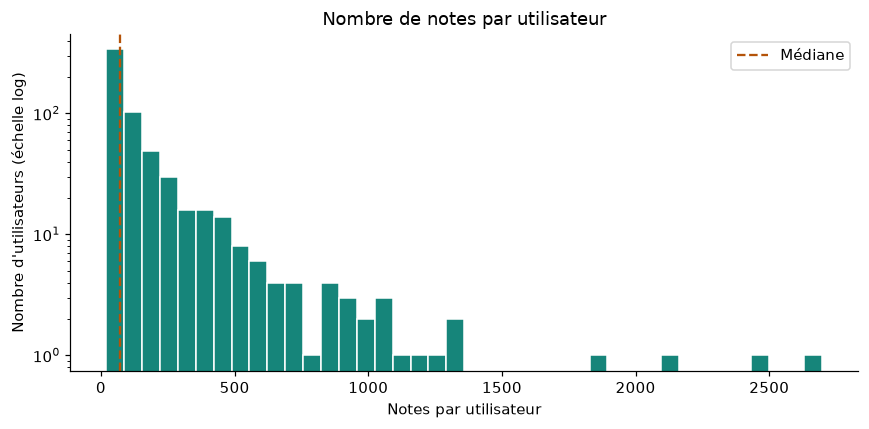

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_user["num_ratings"], bins=40, color="#16857a", edgecolor="white")
ax.axvline(per_user["num_ratings"].median(), color="#b45309", linestyle="--", label="Médiane")
ax.set(title="Nombre de notes par utilisateur", xlabel="Notes par utilisateur",
       ylabel="Nombre d'utilisateurs (échelle log)", yscale="log")
ax.legend()
fig.tight_layout()
plt.show()


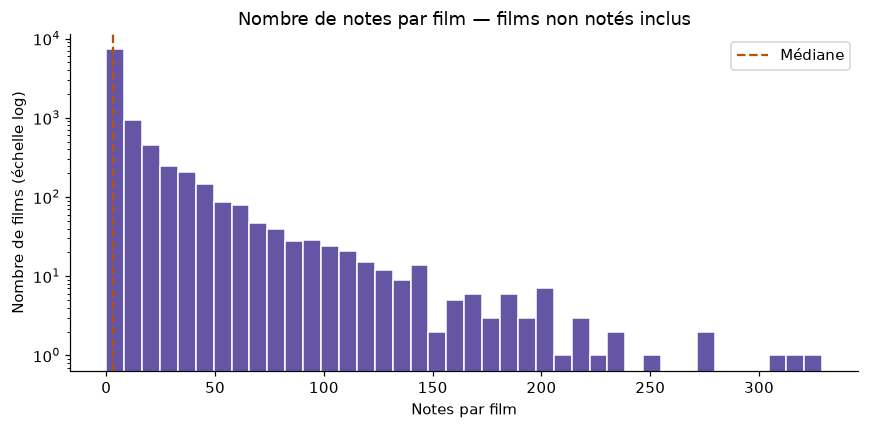

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_movie["num_ratings"], bins=40, color="#6556a5", edgecolor="white")
ax.axvline(per_movie["num_ratings"].median(), color="#b45309", linestyle="--", label="Médiane")
ax.set(title="Nombre de notes par film — films non notés inclus",
       xlabel="Notes par film", ylabel="Nombre de films (échelle log)", yscale="log")
ax.legend()
fig.tight_layout()
plt.show()


La médiane est de 70,5 films par utilisateur, contre 165,3 en moyenne. Quelques utilisateurs très actifs tirent la moyenne vers le haut.

Côté films, la médiane n'est que de trois notes. 66,45 % du catalogue a au plus cinq notes, et 18 films n'en ont aucune. Les moyennes de ces films peu notés sont donc fragiles.

## Genres

Un film peut apparaître dans plusieurs genres : le total du tableau dépasse donc le nombre de films. `(no genres listed)` correspond aux films sans genre renseigné.

In [9]:
genres = genre_counts(movies)
no_genre_mask = movies["genres"].fillna("").isin(["", "(no genres listed)"])
print(f"Genres disponibles ({len(genres)}) : {', '.join(sorted(genres.index))}")
print(f"Films sans genre renseigné : {int(no_genre_mask.sum())} / {len(movies)}")
genre_distribution = genres.to_frame()
genre_distribution["catalog_fraction"] = genres / len(movies)
display(genre_distribution)
display(movies.loc[no_genre_mask].head(10))


Genres disponibles (19) : Action, Adventure, Animation, Children, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, IMAX, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western
Films sans genre renseigné : 34 / 9742


,num_movies,catalog_fraction
genres,,
Drama,4361,0.447649
Comedy,3756,0.385547
Thriller,1894,0.194416
Action,1828,0.187641
Romance,1596,0.163827
Adventure,1263,0.129645
Crime,1199,0.123075
Sci-Fi,980,0.100595
Horror,978,0.100390


,movieId,title,genres
8517,114335,La cravate (1957),(no genres listed)
8684,122888,Ben-hur (2016),(no genres listed)
8687,122896,Pirates of the Caribbean: Dead Men Tell No Tal...,(no genres listed)
8782,129250,Superfast! (2015),(no genres listed)
8836,132084,Let It Be Me (1995),(no genres listed)
8902,134861,Trevor Noah: African American (2013),(no genres listed)
9033,141131,Guardians (2016),(no genres listed)
9053,141866,Green Room (2015),(no genres listed)
9070,142456,The Brand New Testament (2015),(no genres listed)
9091,143410,Hyena Road,(no genres listed)


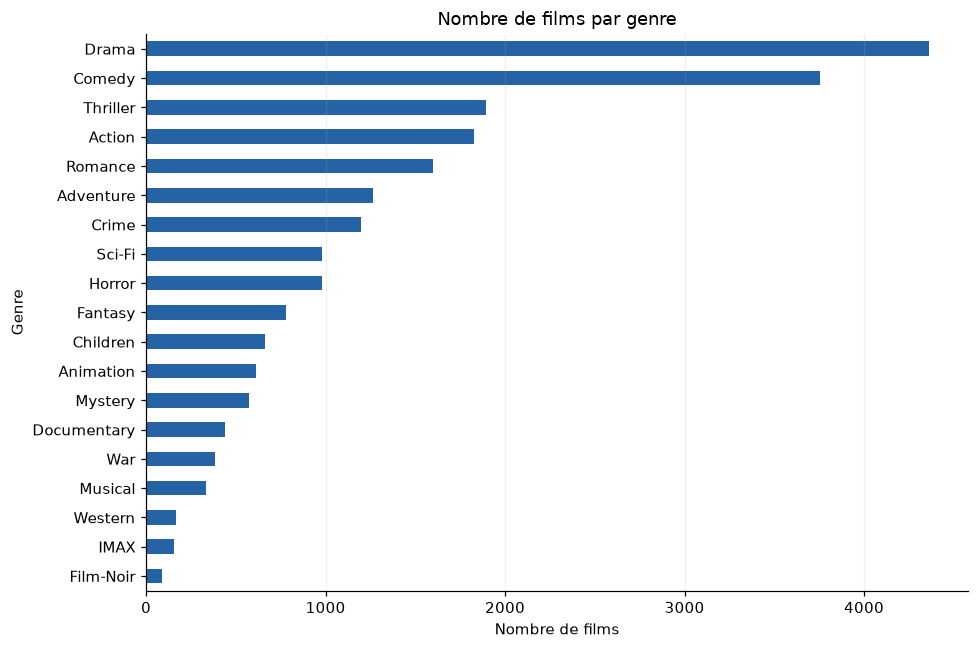

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
genres.sort_values().plot.barh(ax=ax, color="#2563a6")
ax.set(title="Nombre de films par genre", xlabel="Nombre de films", ylabel="Genre")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


Drama et Comedy sont les genres les plus présents. Seuls 34 films n'ont aucun genre indiqué.

Il y a 19 noms dans la liste, dont `IMAX`, qui correspond au format de projection. Il est exclu des genres utilisés pour les recommandations.

## Tags et dates

Le tableau mesure la couverture des tags et leur répartition entre utilisateurs. Les dates indiquent la période couverte par les notes et les tags.

In [11]:
tags_per_user = tags.groupby("userId").size().sort_values(ascending=False)
tag_summary = pd.Series({
    "num_tag_applications": len(tags),
    "num_tagging_users": tags["userId"].nunique(),
    "num_tagged_movies": tags["movieId"].nunique(),
    "tagged_movie_coverage": tags["movieId"].nunique() / len(movies),
    "tagging_user_coverage": tags["userId"].nunique() / num_users,
    "num_distinct_raw_tags": tags["tag"].nunique(),
    "num_distinct_normalized_tags": tags["tag"].str.strip().str.casefold().nunique(),
    "top_tagging_user_fraction": tags_per_user.iloc[0] / len(tags) if len(tags) else 0,
    "repeated_user_movie_pairs": int(tags.duplicated(["userId", "movieId"]).sum()),
}, name="value")
display(tag_summary.to_frame())
display(tags_per_user.head(10).rename("num_tags").to_frame())
display(tags["tag"].value_counts().head(15).rename("num_applications").to_frame())
periods = {}
for name, frame in {"ratings": ratings, "tags": tags}.items():
    dates = pd.to_datetime(frame["timestamp"], unit="s", utc=True)
    periods[name] = {"start_utc": dates.min(), "end_utc": dates.max()}
display(pd.DataFrame(periods).T)


,value
num_tag_applications,3683.000000
num_tagging_users,58.000000
num_tagged_movies,1572.000000
tagged_movie_coverage,0.161363
tagging_user_coverage,0.095082
num_distinct_raw_tags,1589.000000
num_distinct_normalized_tags,1475.000000
top_tagging_user_fraction,0.409177
repeated_user_movie_pairs,1908.000000


,num_tags
userId,
474,1507
567,432
62,370
599,323
477,280
424,273
537,100
125,48
357,45


,num_applications
tag,
In Netflix queue,131
atmospheric,36
superhero,24
thought-provoking,24
funny,23
Disney,23
surreal,23
religion,22
sci-fi,21


,start_utc,end_utc
ratings,1996-03-29 18:36:55+00:00,2018-09-24 14:27:30+00:00
tags,2006-01-13 19:09:12+00:00,2018-09-16 11:50:03+00:00


Les tags ne couvrent que 16,14 % des films. L'utilisateur 474 a renseigné 40,92 % des tags : ses choix de vocabulaire pèseraient beaucoup si on utilisait directement cette colonne.

Les dernières notes datent de septembre 2018. Ce jeu de données convient aux premiers essais, mais ne suffira pas à constituer un catalogue actuel.

## Liens vers TMDB

La jointure entre `movies` et `links` garde tous les films, y compris ceux sans ID TMDB. La présence d'un ID dans ce fichier ne vérifie pas son existence actuelle sur TMDB.

In [12]:
movies_with_links = movies.merge(links, on="movieId", how="left", validate="one_to_one")
tmdb_coverage = movies_with_links["tmdbId"].notna().mean()
missing_tmdb = movies_with_links.loc[movies_with_links["tmdbId"].isna()]
linked_movies = movies_with_links.loc[movies_with_links["tmdbId"].notna()]
tmdb_collisions = linked_movies.loc[linked_movies["tmdbId"].duplicated(keep=False)].sort_values("tmdbId")
ratings_with_links = ratings.merge(links[["movieId", "tmdbId"]], on="movieId", how="left", validate="many_to_one")

mapping_summary = pd.Series({
    "num_catalog_movies": len(movies_with_links),
    "num_movies_with_tmdb": int(movies_with_links["tmdbId"].notna().sum()),
    "num_movies_without_tmdb": len(missing_tmdb),
    "tmdb_coverage": tmdb_coverage,
    "num_distinct_tmdb_ids": linked_movies["tmdbId"].nunique(),
    "num_ambiguous_tmdb_ids": tmdb_collisions["tmdbId"].nunique(),
    "num_movies_in_tmdb_collisions": len(tmdb_collisions),
    "num_ratings_without_tmdb": int(ratings_with_links["tmdbId"].isna().sum()),
    "rating_tmdb_coverage": ratings_with_links["tmdbId"].notna().mean(),
}, name="value")
display(mapping_summary.to_frame())
print(f"Couverture du catalogue : {tmdb_coverage:.4%}")
display(Markdown("Films sans ID TMDB"))
display(missing_tmdb)
display(Markdown("ID TMDB associé à plusieurs films"))
display(tmdb_collisions.merge(per_movie, on="movieId", validate="one_to_one"))


,value
num_catalog_movies,9742.000000
num_movies_with_tmdb,9734.000000
num_movies_without_tmdb,8.000000
tmdb_coverage,0.999179
num_distinct_tmdb_ids,9733.000000
num_ambiguous_tmdb_ids,1.000000
num_movies_in_tmdb_collisions,2.000000
num_ratings_without_tmdb,13.000000
rating_tmdb_coverage,0.999871


Couverture du catalogue : 99.9179%


Films sans ID TMDB

,movieId,title,genres,imdbId,tmdbId
624,791,"Last Klezmer: Leopold Kozlowski, His Life and ...",Documentary,0113610,<NA>
843,1107,Loser (1991),Comedy,0102336,<NA>
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller,0081454,<NA>
3027,4051,Horrors of Spider Island (Ein Toter Hing im Ne...,Horror|Sci-Fi,0056600,<NA>
5532,26587,"Decalogue, The (Dekalog) (1989)",Crime|Drama|Romance,0092337,<NA>
5854,32600,Eros (2004),Drama,0377059,<NA>
6059,40697,Babylon 5,Sci-Fi,0105946,<NA>
7382,79299,"No. 1 Ladies' Detective Agency, The (2008)",Comedy|Crime|Mystery,0874957,<NA>


ID TMDB associé à plusieurs films

,movieId,title,genres,imdbId,tmdbId,num_ratings,avg_rating
0,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller,0290538,4912,15,3.6
1,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller,0270288,4912,1,4.0


99,92 % des films ont un ID TMDB. Il reste huit films sans cet ID.

L'ID TMDB `4912` apparaît sur deux lignes MovieLens. Elles ont le même titre, mais des genres et des IDs IMDb différents. Si on cherche le film MovieLens à partir de cet ID TMDB, on obtient donc deux réponses.

## Contrôles

Les totaux des notes par utilisateur et par film doivent correspondre au nombre de lignes de `ratings`. Les films sans genre et les deux entrées partageant le même ID TMDB restent dans les tableaux.

In [13]:
assert quality["duplicate_rows"].eq(0).all(), "Examiner les lignes dupliquées."
assert quality.loc[["movies", "links", "ratings"], "duplicate_keys"].eq(0).all(), "Examiner les clés dupliquées."
assert reference_checks.eq(0).all(), "Examiner les références et valeurs invalides."
assert per_user["num_ratings"].sum() == num_ratings
assert per_movie["num_ratings"].sum() == num_ratings
assert len(per_movie) == len(movies)
assert 0 <= tmdb_coverage <= 1
print("Contrôles OK.")


Contrôles OK.


## Limites des données

Les 34 films sans genre ne peuvent pas être classés par similarité de genres. Huit films n'ont pas d'ID TMDB, et l'ID `4912` est partagé par deux films MovieLens. La conversion des identifiants doit prendre ces cas en compte.

Les moyennes des films peu notés restent fragiles : 66,45 % du catalogue a au plus cinq notes. `movieId` sert de clé pour les films ; les titres ne sont pas uniques.

### Chiffres du catalogue

La moyenne de notes par film inclut les 18 films non notés. `tmdb_coverage` est la proportion de films ayant un ID TMDB renseigné, entre 0 et 1.

In [14]:
summary = summarize_dataset(tables)
assert summary["tmdb_coverage"] == float(tmdb_coverage)
print(json.dumps(summary, indent=4, ensure_ascii=False))


{
    "num_movies": 9742,
    "num_users": 610,
    "num_ratings": 100836,
    "avg_ratings_per_user": 165.30491803278687,
    "avg_ratings_per_movie": 10.350646684459043,
    "tmdb_coverage": 0.9991788133853419
}
